# Workshop-3: Exploratory Data Analysis & Schema Harmonization
## Academic Course: ETL (G01) - Data Engineering & AI
### Objective
Inspect raw historical World Happiness datasets (2015-2019), identify schema differences, missing values, duplicates, and outliers, and build a unified analytical schema for downstream ML and streaming.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print('Environment and libraries ready.')


Environment and libraries ready.


## 1. Inspecting Raw Datasets (2015 - 2019)
We load the five CSV files located in `../data/raw/` and inspect their shapes, column structures, and data types.


In [2]:
raw_data_dir = '../data/raw'
years = [2015, 2016, 2017, 2018, 2019]
raw_dfs = {}

for y in years:
    path = os.path.join(raw_data_dir, f'{y}.csv')
    raw_dfs[y] = pd.read_csv(path)
    print(f'Year {y}: Shape = {raw_dfs[y].shape}, Columns = {len(raw_dfs[y].columns)}')


Year 2015: Shape = (158, 12), Columns = 12
Year 2016: Shape = (157, 13), Columns = 13
Year 2017: Shape = (155, 12), Columns = 12
Year 2018: Shape = (156, 9), Columns = 9
Year 2019: Shape = (156, 9), Columns = 9


## 2. Schema Differences & Column Name Inconsistencies
Notice how column names change across years. In 2015 and 2016 names contain spaces and parentheses. In 2017 names contain dots. In 2018 and 2019 names are shorter, and column count dropped from 12-13 to 9.


In [3]:
schema_summary = []
for y in years:
    cols = raw_dfs[y].columns.tolist()
    schema_summary.append({
        'Year': y,
        'Num_Rows': raw_dfs[y].shape[0],
        'Num_Cols': raw_dfs[y].shape[1],
        'Columns': cols
    })

for item in schema_summary:
    print(f"=== YEAR {item['Year']} ===")
    print(item['Columns'])
    print()


=== YEAR 2015 ===
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

=== YEAR 2016 ===
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

=== YEAR 2017 ===
['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']

=== YEAR 2018 ===
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']

=== YEAR 2019 ===
['Overall ra

## 3. Data Quality Audit: Missing Values & Duplicates
We check for null values and duplicated rows in all datasets.


In [4]:
print('--- DUPLICATE ROWS CHECK ---')
for y in years:
    dups = raw_dfs[y].duplicated().sum()
    print(f'{y}: {dups} duplicated rows.')

print('\n--- MISSING VALUES (NaN) CHECK ---')
for y in years:
    nulls = raw_dfs[y].isnull().sum()
    null_cols = nulls[nulls > 0]
    if len(null_cols) > 0:
        print(f'Year {y} has missing values:\n{null_cols}')
    else:
        print(f'Year {y}: 0 missing values.')


--- DUPLICATE ROWS CHECK ---
2015: 0 duplicated rows.
2016: 0 duplicated rows.
2017: 0 duplicated rows.
2018: 0 duplicated rows.
2019: 0 duplicated rows.

--- MISSING VALUES (NaN) CHECK ---
Year 2015: 0 missing values.
Year 2016: 0 missing values.
Year 2017: 0 missing values.
Year 2018 has missing values:
Perceptions of corruption    1
dtype: int64
Year 2019: 0 missing values.


In [5]:
# Inspect the single missing value in 2018
df_2018 = raw_dfs[2018]
missing_uae = df_2018[df_2018['Perceptions of corruption'].isnull()]
missing_uae[['Overall rank', 'Country or region', 'Score', 'Perceptions of corruption']]


,Overall rank,Country or region,Score,Perceptions of corruption
19,20,United Arab Emirates,6.774,NaN


## 4. Data Quality Observations & Target Leakage Prevention

### Observations:
1. **Schema Evolution:**
   - 2015-2016 include `Region`, `Standard Error` / `Confidence Interval`, and `Dystopia Residual`.
   - 2017 switched formatting to dot notation (e.g., `Economy..GDP.per.Capita.`, `Happiness.Score`).
   - 2018-2019 dropped `Region` and error metrics, renamed `Country` to `Country or region`, and `Family` to `Social support`.
2. **Missing Values:**
   - Only 1 missing value exists across all 782 records: `Perceptions of corruption` for `United Arab Emirates` in 2018.
3. **Duplicates:** Zero duplicated rows across all 5 years.
4. **Target Leakage Risks (Critical):**
   - `Happiness Rank` / `Overall rank`: Directly computed by ranking `Happiness Score`. Using it as an input feature would be pure target leakage.
   - `Dystopia Residual`: Component mathematically tied to the target sum ($Score = Sum(factors) + Residual$).
   - `Standard Error` / `Confidence Intervals`: Variance estimates directly measuring the target score's distribution.
   - **Conclusion:** Features must be restricted to the 6 core explanatory metrics: `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`.


## 5. Unified Schema Proposal
We define an analytical `snake_case` schema matching the Kafka Event Contract:

| Unified Column | Type | Source 2015-2016 | Source 2017 | Source 2018-2019 | Description |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `country` | string | `Country` | `Country` | `Country or region` | Standardized country name |
| `region` | string | `Region` | Inferred / Reference | Inferred / Reference | Geographic region |
| `year` | integer | Generated (2015/16) | Generated (2017) | Generated (2018/19) | Observation year |
| `actual_happiness_score` | float | `Happiness Score` | `Happiness.Score` | `Score` | Target variable (evaluation only) |
| `gdp` | float | `Economy (GDP per Capita)` | `Economy..GDP.per.Capita.` | `GDP per capita` | Feature 1: Economic output |
| `family` | float | `Family` | `Family` | `Social support` | Feature 2: Social/family support |
| `health` | float | `Health (Life Expectancy)` | `Health..Life.Expectancy.` | `Healthy life expectancy` | Feature 3: Life expectancy |
| `freedom` | float | `Freedom` | `Freedom` | `Freedom to make life choices` | Feature 4: Freedom of choice |
| `generosity` | float | `Generosity` | `Generosity` | `Generosity` | Feature 5: Generosity score |
| `corruption` | float | `Trust (Government Corruption)`| `Trust..Government.Corruption.`| `Perceptions of corruption` | Feature 6: Absence of corruption |


## 6. Implementation of Cleaning and Harmonization
We execute the standardized transformation and export the unified dataset to `../data/processed/happiness_unified.csv`.


In [6]:
sys.path.append('..')
from src.harmonization import load_and_harmonize_data, export_processed_datasets

unified_df = export_processed_datasets(
    output_processed_dir='../data/processed',
    output_streaming_dir='../data/streaming'
)

print('Harmonized Dataset Head:')
unified_df.head()


Exported unified dataset to ../data/processed\happiness_unified.csv (Shape: (782, 10))

Exported streaming source dataset to ../data/streaming\happiness_stream_source.csv (Shape: (782, 10))


Harmonized Dataset Head:


,country,region,year,actual_happiness_score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,Western Europe,2015,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,Western Europe,2015,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,Western Europe,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,Western Europe,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,North America,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


## 7. Descriptive Statistics and Visual Outlier Analysis


In [7]:
print('Unified Dataset Descriptive Statistics:')
print(unified_df.describe().round(4))


Unified Dataset Descriptive Statistics:
            year  actual_happiness_score       gdp    family    health  \
count   782.0000                782.0000  782.0000  782.0000  782.0000   
mean   2016.9936                  5.3790    0.9160    1.0784    0.6124   
std       1.4174                  1.1275    0.4073    0.3295    0.2483   
min    2015.0000                  2.6930    0.0000    0.0000    0.0000   
25%    2016.0000                  4.5098    0.6065    0.8694    0.4402   
50%    2017.0000                  5.3220    0.9822    1.1247    0.6473   
75%    2018.0000                  6.1895    1.2362    1.3272    0.8080   
max    2019.0000                  7.7690    2.0960    1.6440    1.1410   

        freedom  generosity  corruption  
count  782.0000    782.0000    782.0000  
mean     0.4111      0.2186      0.1257  
std      0.1529      0.1223      0.1060  
min      0.0000      0.0000      0.0000  
25%      0.3098      0.1300      0.0542  
50%      0.4310      0.2020      0.0910  

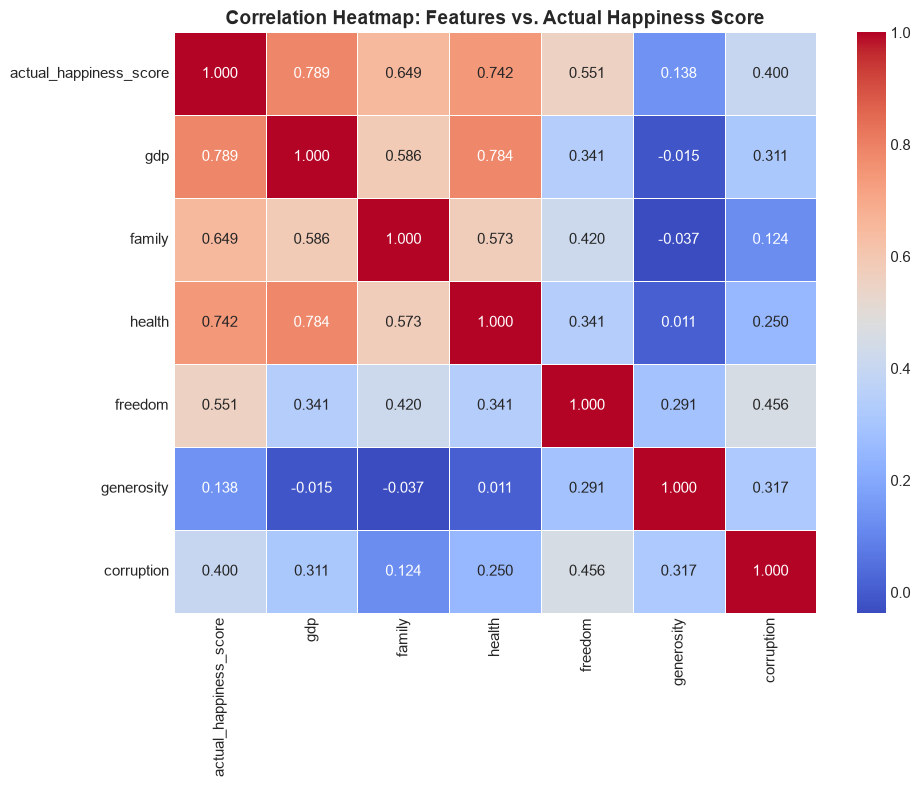

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
numeric_cols = ['actual_happiness_score', 'gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
corr = unified_df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', cbar=True, ax=ax, linewidths=0.5)
ax.set_title('Correlation Heatmap: Features vs. Actual Happiness Score', fontsize=14, fontweight='bold')
plt.tight_layout()
os.makedirs('../dashboards', exist_ok=True)
plt.savefig('../dashboards/correlation_heatmap.png', dpi=300)
plt.show()


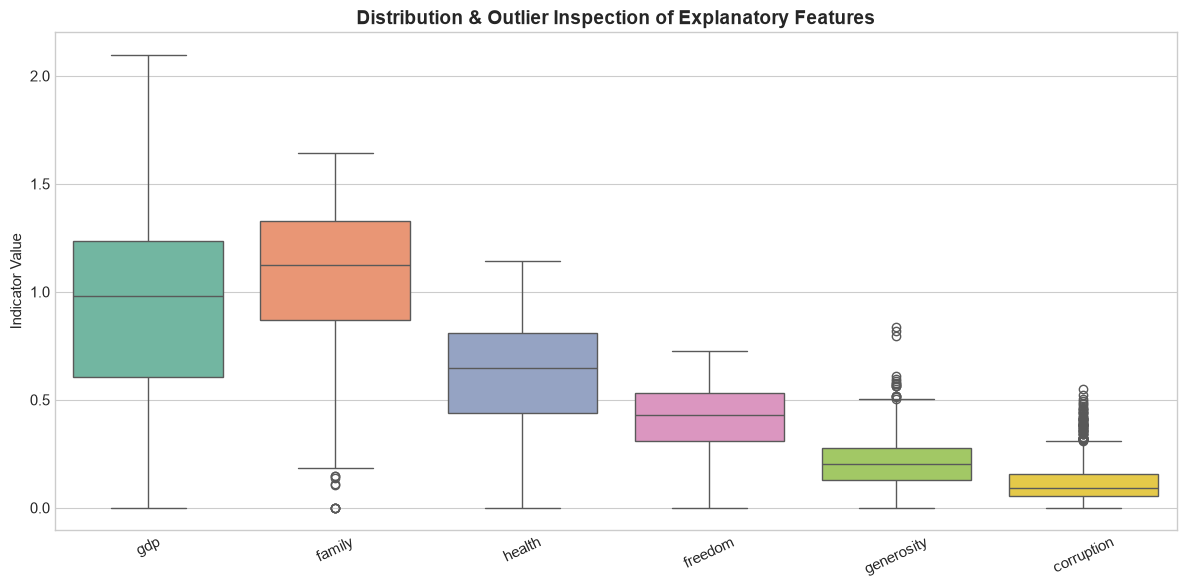

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=unified_df[numeric_cols[1:]], ax=ax, palette='Set2')
ax.set_title('Distribution & Outlier Inspection of Explanatory Features', fontsize=14, fontweight='bold')
ax.set_ylabel('Indicator Value')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig('../dashboards/features_boxplot.png', dpi=300)
plt.show()


## 8. Conclusion of Step 1 & Step 2
- Total observations harmonized: **782 records** across 5 years.
- Zero missing values remaining after justified median imputation of UAE 2018 corruption.
- Clear, leakage-free feature subset identified: `['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']`.
- Unified dataset exported to `../data/processed/happiness_unified.csv`.
